Import thư viện và đọc dữ liệu California Housing

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBRegressor

# Đọc dữ liệu California Housing
df = pd.read_csv("california_housing.csv")
print("Kích thước dữ liệu:", df.shape)
print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())
print("\nTên các cột:")
print(df.columns.tolist())

Kích thước dữ liệu: (20640, 9)

5 dòng dữ liệu đầu tiên:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Tên các cột:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


EDA


Số giá trị thiếu mỗi cột


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Thống kê mô tả dữ liệu


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


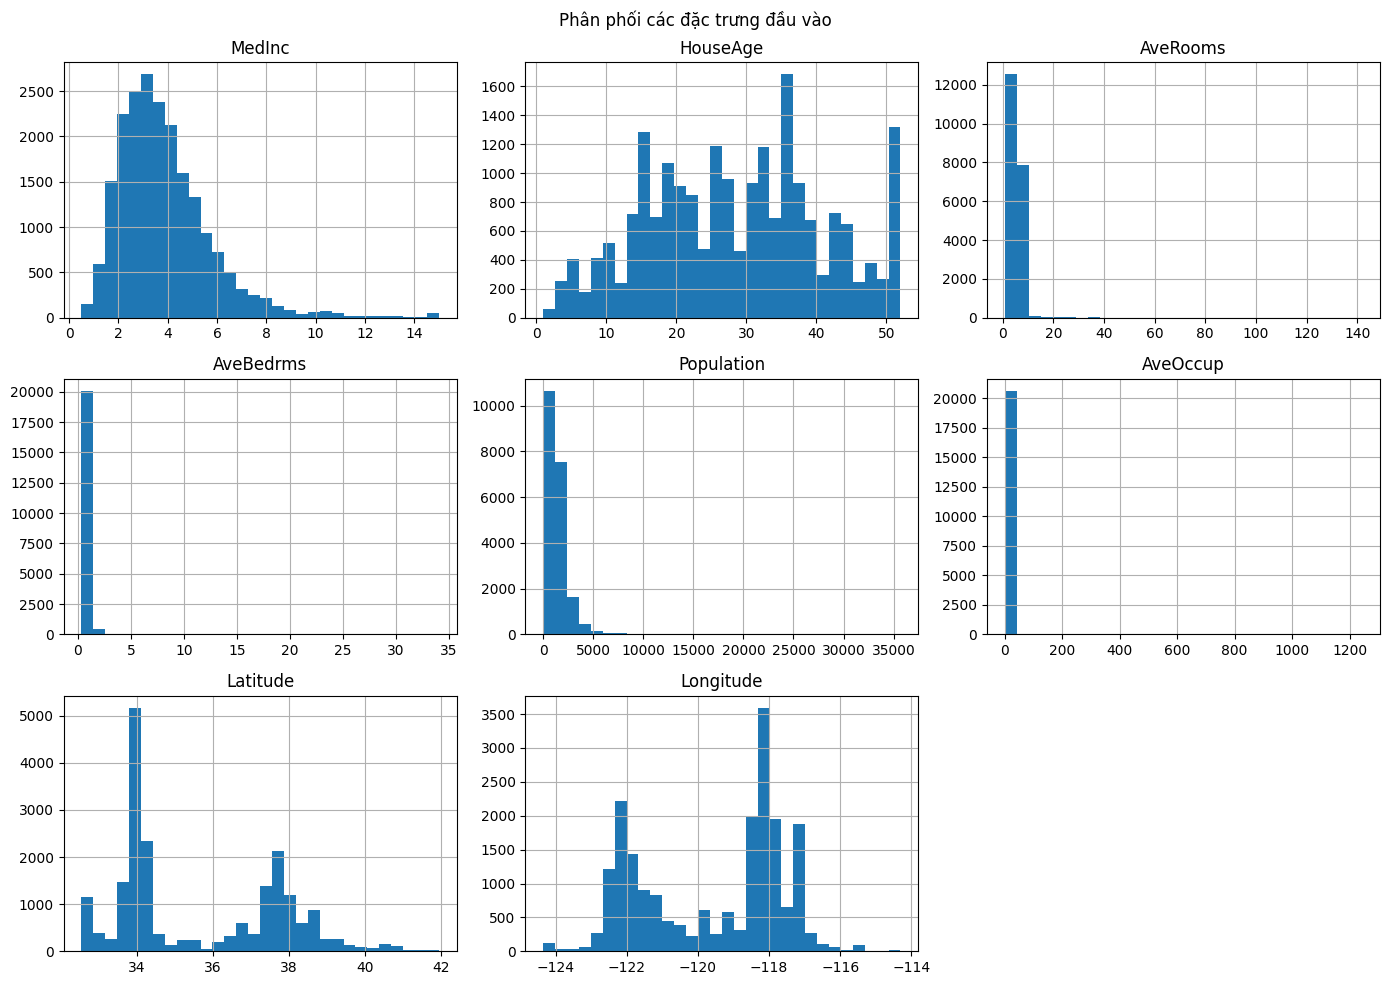

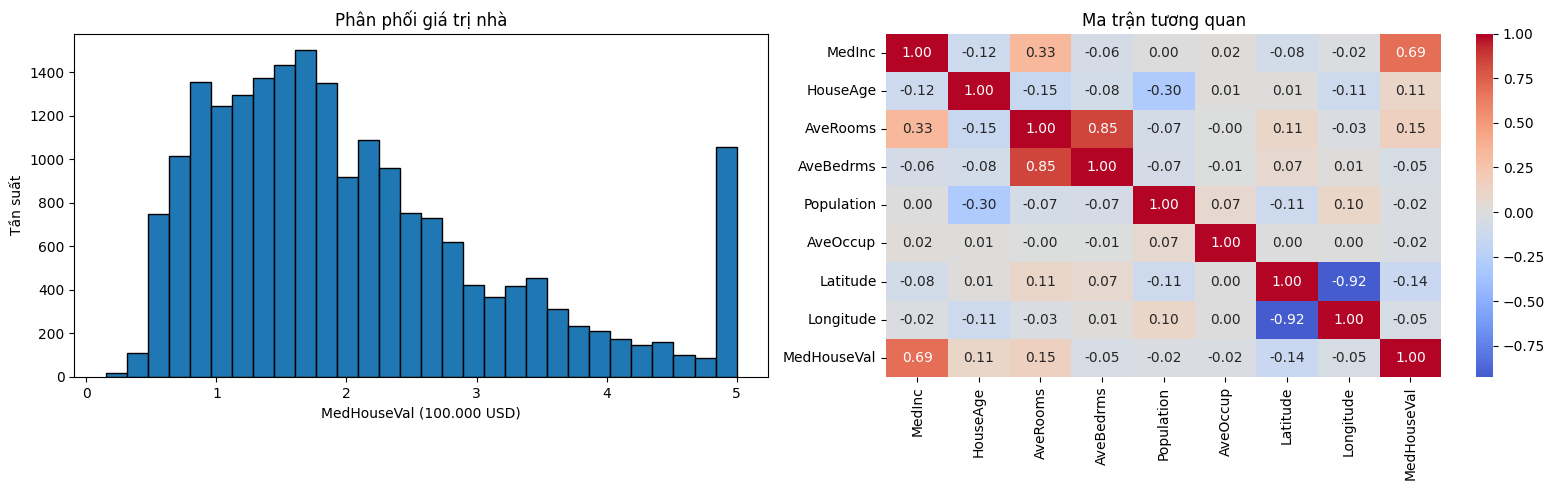

In [ ]:
# Kiểm tra giá trị thiếu
print("\nSố giá trị thiếu mỗi cột")
display(df.isna().sum())

# Thống kê mô tả dữ liệu
print("\nThống kê mô tả dữ liệu")
display(df.describe().round(2))

# Phân phối các đặc trưng đầu vào
X_eda = df.drop(columns=["MedHouseVal"])
X_eda.hist(figsize=(14, 10), bins=30)
plt.suptitle("Phân phối các đặc trưng đầu vào")
plt.tight_layout()
plt.show()


# Phân phối biến mục tiêu và ma trận tương quan
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Phân phối biến mục tiêu
axes[0].hist(df["MedHouseVal"], bins=30, edgecolor="black")
axes[0].set_xlabel("MedHouseVal (100.000 USD)")
axes[0].set_ylabel("Tần suất")
axes[0].set_title("Phân phối giá trị nhà")

# Ma trận tương quan
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)
axes[1].set_title("Ma trận tương quan")

plt.tight_layout()
plt.show()

Chia dữ liệu thành tập huấn luyện và tập kiểm tra (Train-Test Split)

In [24]:
# Chia dữ liệu thành đặc trưng X và biến mục tiêu y
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# Chia dữ liệu: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

Kích thước X_train: (16512, 8)
Kích thước X_test: (4128, 8)
Kích thước y_train: (16512,)
Kích thước y_test: (4128,)


Xây dựng và huấn luyện mô hình XGBoost Regression.

In [25]:
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Huấn luyện mô hình hoàn tất!")

Huấn luyện mô hình hoàn tất!


Đánh giá mô hình XGBoost Regression

In [ ]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("Kết quả đánh giá mô hình")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

Kết quả đánh giá mô hình
MAE:  0.3534
MSE:  0.2720
RMSE: 0.5215
R²:   0.7924


Trực quan hóa kết quả dự đoán và độ quan trọng của đặc trưng

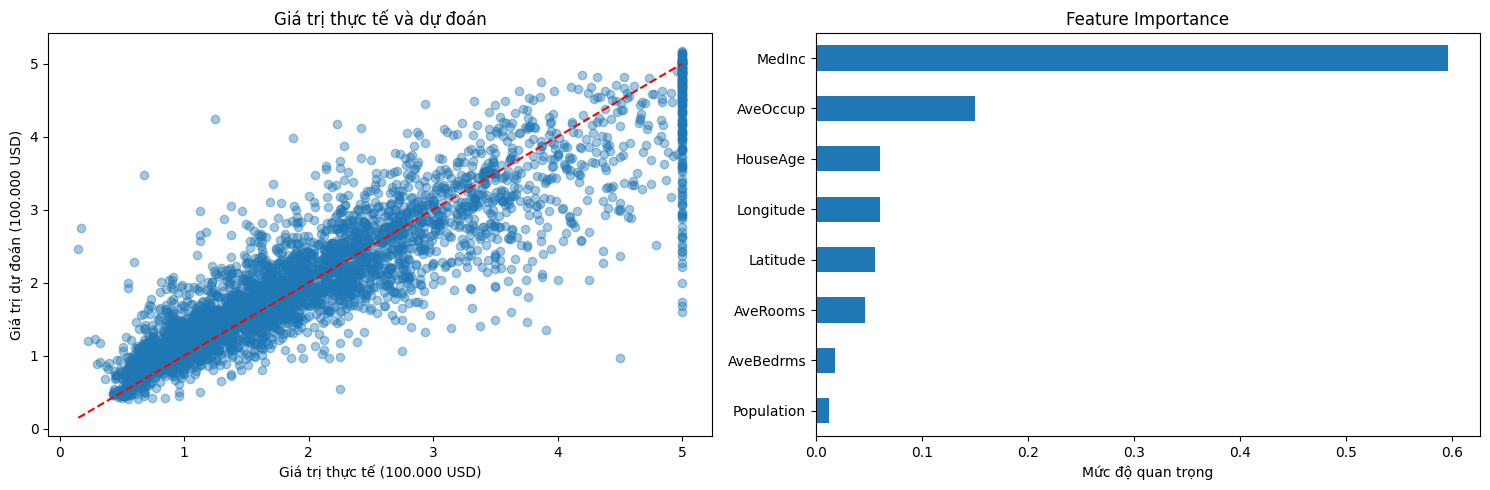

In [ ]:
# Trực quan hóa kết quả mô hình
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Giá trị thực tế và giá trị dự đoán
axes[0].scatter(y_test, y_pred, alpha=0.4)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
axes[0].set_xlabel("Giá trị thực tế (100.000 USD)")
axes[0].set_ylabel("Giá trị dự đoán (100.000 USD)")
axes[0].set_title("Giá trị thực tế và dự đoán")

# 2. Độ quan trọng của các đặc trưng
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values()

importance.plot(kind="barh", ax=axes[1])
axes[1].set_xlabel("Mức độ quan trọng")
axes[1].set_title("Feature Importance")

plt.tight_layout()
plt.show()